<a href="https://colab.research.google.com/github/plnu-biomechanics/kin4042/blob/main/notebooks/kin4042_lab5_key.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://www.pointloma.edu/sites/default/files/styles/basic_page/public/images/PLNU_Biomechanics_Lab_green_yellowSD_HiRes.png" width=400>

## **KIN 4042 Sports Informatics**
Instructor: Arnel Aguinaldo, PhD

**Lab 5: Analyzing time-series signals**

In this lab, running gait analysis data was collected with carbon-fiber plated (CFP) and training (TRN) shoes. Inverse kinematics (IK) and kinetics via inverse dynamics were estimated using Visual3D. The data were then exported as text (*.txt) files and uploaded to the class repository in the lab's GitHub.

To further process the data for this lab, follow the steps in this **Colab notebook**, which contains instructions and sample code on how to wrangle and analyze the data.


### Create your own Colab Notebook

1. Go to **File -> New notebook in Drive** to open a new notebook in your Python environment:<br>
<img src="https://raw.githubusercontent.com/plnu-biomechanics/kin6015/main/notebooks/images/file_notebook.png" width=450>

2. Rename your Colab notebook using this naming format: **lastname_kin4042_lab#.ipynb** (e.g., "aguinaldo_kin4042_lab1.ipynb")
3. Click on the **+ Code** option above to insert a new code cell: <br>
<img src="https://raw.githubusercontent.com/plnu-biomechanics/kin6015/main/notebooks/images/addcode.png" width=280>

4. The data you will parse and analyze for this lab will be temporarily stored in your Colab's runtime directory, which can be accessed by clicking on the folder icon in the left menu:<br>
<img src="https://raw.githubusercontent.com/plnu-biomechanics/kin6015/main/notebooks/images/colab_folder.png" width=400>

5. Copy the following lines of code to import the packages needed for this analysis and to load the data files into your working directory. **Note**: These files are "runtime" access only, meaning they are only temporarily stored in your working directory and show up when your notebook is in session.


## 🔄 Data Ingestion

Let's now pull data from the PLNU Biomechanics Lab repository on GitHub.

In [5]:
# Import the required libraries
import os
import urllib.request

data_dir = "kin4042/lab5"
os.makedirs(data_dir, exist_ok=True)

#

# This is the raw URLs for the high performance data files (*.csv) on GitHub
running_url = (
    "https://raw.githubusercontent.com/plnu-biomechanics/kin4042/"
    "refs/heads/main/labs/lab5_running_kinematics.csv"
)

# Define filepaths on your working directory
df_filename = "lab5_running_kinematics.csv"
df_path = os.path.join(data_dir, df_filename)

# --------------------------------------------------
# Download files directly from GitHub
# --------------------------------------------------
urllib.request.urlretrieve(running_url, df_path)

print("Existing files in the lab directory:")
print(os.listdir(data_dir))

Existing files in the lab directory:
['lab5_running_kinematics.csv']


## 📈 Statistical Parametric Mapping (SPM)

Statistical parametric mapping (SPM) uses Random Field Theory to make statistical inferences about normalized sets of biomechanical variables across time (1D). It can be used to compare kinematic, kinetic, or EMG time-series curves using traditional NHST statistical tests such as a t-test, ANOVA, and linear regression. In this course, we will be using the package, `spm1d`, in [Python](https://spm1d.org/index.html) to perform some basic SPM analyses.

Before we perform the SPM analyses, we must prepare the time-series data so that they can be properly structured for SPM. The process of preparing and organizing raw data into usable data is known as **data wrangling**. For SPM, the time-series data must be structured so that each variable for each condition (i.e., conventional, sumo) is its own data file, where the data is organized in a *JxQ* array:

* J = number of trials or subjects
* Q = number of frames or time points (i.e., 100)

The following code wrangles the time-series data in these arrays and exports them into individual text files for subsequent SPM analysis. This will allow the `spm1d` package to average the data at each frame across all trials in a process known as **ensemble averaging** where the solid thick lines represent the mean and the semi-transparent bands represent the +/- 1 standard deviation:

<img src="https://raw.githubusercontent.com/plnu-biomechanics/kin6015/main/notebooks/images/SPM_plot_sample.png">

This two-line cell installs the `spm1d` library in runtime environment and confirms installation.

## 🔄 Data Frames

<img src="https://raw.githubusercontent.com/plnu-biomechanics/kin4042/main/notebooks/images/pandas_logo.jpg" width=400>

Before the data can be analyzed, they need to be parsed into what are called `DataFrames`, which are two-dimensional tabular data structure with labeled columns and rows. Think of them like spreadsheets with an organized structure that can be manipulated and analyzed in Python.

In this lab, we will use the powerful `pandas` library to create a data frame from the `lab5_running_kinematics.csv`.

You can use your favorite GenAI agent to help you with populating these two data frames.

### ✋ GenAI prompt:
Generate code that will load a data frame with data from the `*.csv` file as well as inspect and print out the column name for each variable for analysis. Count the number of unique players, conditions, and frames per player included in the data frame made for `lab5_running_kinematics.csv`.

*Note: Be sure to state in a comment the GenAI agent you used to generate the code similar to this comment:*

```
# =======================================
#  Code generated or assisted by Claude
# =======================================
```



In [7]:
# =======================================
#  Code generated or assisted by ChatGPT
# =======================================
import pandas as pd
import os

# Define paths based on the previous cell configuration
data_dir = "kin4042/lab5"
df_filename = "lab5_running_kinematics.csv"
df_path = os.path.join(data_dir, df_filename)

# Load the DataFrame
running_df = pd.read_csv(df_path)

# 1. Inspect and print out column names
print("=== Column Names in DataFrame ===")
print(running_df.columns.tolist())
print("\n")

# 2. Count unique players
unique_players = running_df['player_id'].nunique()
print(f"Number of unique players: {unique_players}")

# 3. Count unique conditions
unique_conditions = running_df['group'].nunique()
print(f"Number of unique conditions (groups): {unique_conditions} {running_df['group'].unique().tolist()}")

# 4. Count frames per player
print("\n=== Frames per Player ===")
frames_per_player = running_df.groupby('player_id')['frame'].count()
print(frames_per_player)

=== Column Names in DataFrame ===
['player_id', 'group', 'frame', 'knee_flexion', 'ankle_dorsiflexion', 'foot_rotation']


Number of unique players: 10
Number of unique conditions (groups): 2 ['training', 'carbonfiber']

=== Frames per Player ===
player_id
1001    101
1002    101
1003    101
1004    101
1005    101
1006    101
1007    101
1008    101
1009    101
1010    101
Name: frame, dtype: int64


In [6]:
# =======================================
#  Code generated or assisted by Claude
# =======================================
import pandas as pd
import os

# Define paths
data_dir = "kin4042/lab5"

# Load DataFrames
running_df = pd.read_csv(df_path)

# print column headers
print("=== Data Columns ===")
print(running_df.head())


=== Data Columns ===
   player_id     group  frame  knee_flexion  ankle_dorsiflexion  foot_rotation
0       1001  training      1      52.82267             4.03551        1.07527
1       1001  training      2      52.87486             5.01197        0.55293
2       1001  training      3      52.48185             6.44120        0.06555
3       1001  training      4      51.72203             8.31180       -0.37283
4       1001  training      5      50.73232            10.59001       -0.75666


### 🔄 Data Wrangling: Restructuring to $J \times Q$ Arrays for SPM

For `spm1d` analyses, the time-series data must be formatted as a $J \times Q$ array (where rows $J$ are subjects/trials, and columns $Q$ are normalized percentage timepoints or frames, here $101$ frames). We will pivot our `running_df` to create these arrays for each variable (`knee_flexion`, `ankle_dorsiflexion`, `foot_rotation`) and each shoe condition (`training`, `carbonfiber`).

In [8]:
# =======================================
#  Code generated or assisted by Colab
# =======================================
import numpy as np
import pandas as pd
import os

# Variables to extract
kinematic_vars = ['knee_flexion', 'ankle_dorsiflexion', 'foot_rotation']
conditions = ['training', 'carbonfiber']

print("=== Restructuring Data into JxQ Arrays ===\n")

for var in kinematic_vars:
    for cond in conditions:
        # Filter by condition
        sub_df = running_df[running_df['group'] == cond]

        # Pivot to obtain rows as players (J) and columns as frames (Q)
        # Index is 'player_id', Columns is 'frame', Values is the kinematic variable
        jq_df = sub_df.pivot(index='player_id', columns='frame', values=var)

        # Convert to numpy array
        jq_array = jq_df.to_numpy()

        # Verify shape
        print(f"Variable: {var} | Condition: {cond}")
        print(f"  - Players (J): {jq_array.shape[0]}")
        print(f"  - Frames (Q): {jq_array.shape[1]}")
        print(f"  - Array Shape: {jq_array.shape}")

        # Export to a text file for spm1d
        output_filename = f"{var}_{cond}_JxQ.txt"
        output_path = os.path.join(data_dir, output_filename)
        np.savetxt(output_path, jq_array, fmt='%.5f')
        print(f"  - Saved to: {output_path}\n")

=== Restructuring Data into JxQ Arrays ===

Variable: knee_flexion | Condition: training
  - Players (J): 5
  - Frames (Q): 101
  - Array Shape: (5, 101)
  - Saved to: kin4042/lab5/knee_flexion_training_JxQ.txt

Variable: knee_flexion | Condition: carbonfiber
  - Players (J): 5
  - Frames (Q): 101
  - Array Shape: (5, 101)
  - Saved to: kin4042/lab5/knee_flexion_carbonfiber_JxQ.txt

Variable: ankle_dorsiflexion | Condition: training
  - Players (J): 5
  - Frames (Q): 101
  - Array Shape: (5, 101)
  - Saved to: kin4042/lab5/ankle_dorsiflexion_training_JxQ.txt

Variable: ankle_dorsiflexion | Condition: carbonfiber
  - Players (J): 5
  - Frames (Q): 101
  - Array Shape: (5, 101)
  - Saved to: kin4042/lab5/ankle_dorsiflexion_carbonfiber_JxQ.txt

Variable: foot_rotation | Condition: training
  - Players (J): 5
  - Frames (Q): 101
  - Array Shape: (5, 101)
  - Saved to: kin4042/lab5/foot_rotation_training_JxQ.txt

Variable: foot_rotation | Condition: carbonfiber
  - Players (J): 5
  - Frames

### 📈 Ensemble Average Kinematic Curve Visualizations

Let's plot the ensemble averages (mean ± 1 standard deviation bands) to visually compare the `training` vs. `carbonfiber` shoe conditions for knee flexion, ankle dorsiflexion, and foot rotation across the running cycle.

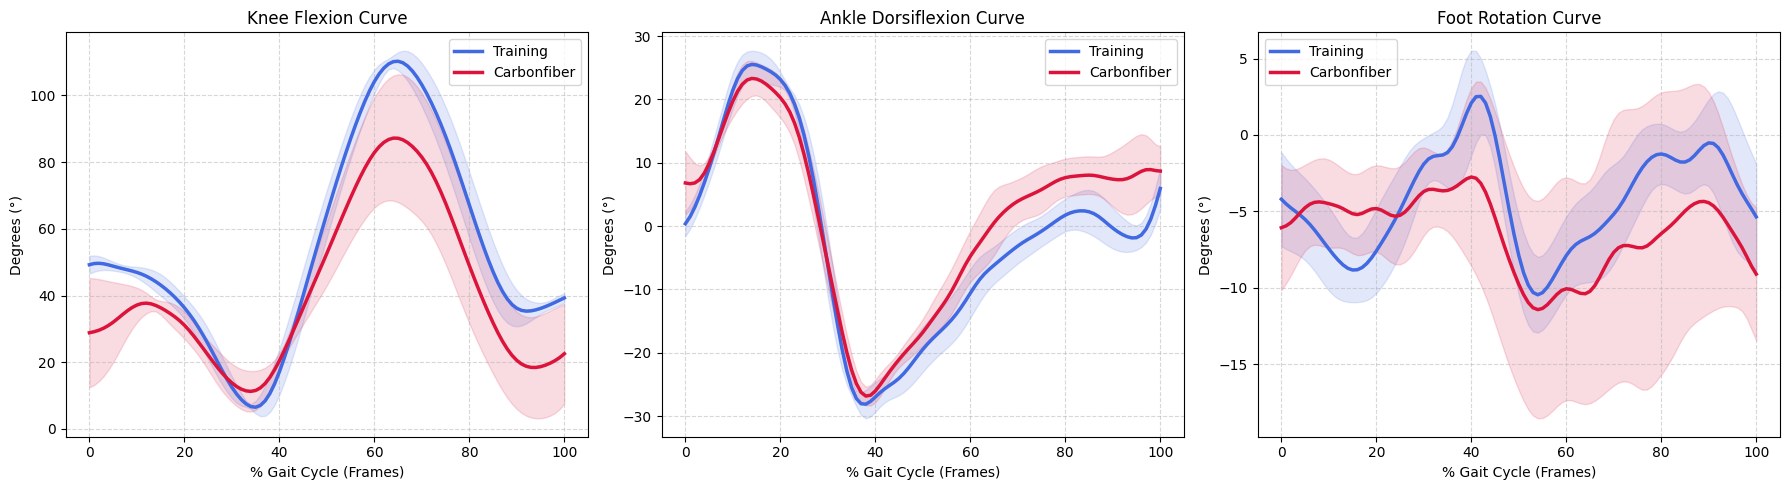

In [9]:
# =======================================
#  Code generated or assisted by Colab
# =======================================
import numpy as np
import matplotlib.pyplot as plt
import os

kinematic_vars = ['knee_flexion', 'ankle_dorsiflexion', 'foot_rotation']
frames = np.arange(101)  # 0% to 100% of the movement cycle

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {'training': 'royalblue', 'carbonfiber': 'crimson'}

for idx, var in enumerate(kinematic_vars):
    ax = axes[idx]
    for cond in ['training', 'carbonfiber']:
        # Load the saved JxQ data
        file_path = os.path.join(data_dir, f"{var}_{cond}_JxQ.txt")
        data = np.loadtxt(file_path)

        # Compute mean and standard deviation across trials (axis 0)
        mean_curve = np.mean(data, axis=0)
        std_curve = np.std(data, axis=0)

        # Plot mean line
        ax.plot(frames, mean_curve, color=colors[cond], label=cond.capitalize(), lw=2.5)
        # Plot +/- 1 standard deviation band
        ax.fill_between(frames, mean_curve - std_curve, mean_curve + std_curve,
                        color=colors[cond], alpha=0.15)

    ax.set_title(f"{var.replace('_', ' ').title()} Curve")
    ax.set_xlabel('% Gait Cycle (Frames)')
    ax.set_ylabel('Degrees (°)')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 📓Lab Note

Take note of the number of players with sprint time data in each data frame and the number of trials per player (range is fine).

## 📈 Inspection

In this lab, the dependent variable of interest is **sprint time** (`Total` from `plnu_hp_smartspeed_30yd`), which is used to operationally define high-speed running performance. We are also interested in how **jump height** and **peak power** influence **sprint time**.

First, we need to inspect the quality of the variables of interest by checking for missing values and outliers.


## 📓Lab Note

Take note of the final number of players with speed data and the number of trials per player after data sanitization.

## 📊 Data Visualization: Summary Statistics

Let's visualize the descriptive statistics from `cmj_df_cleaned` and `speed_df_cleaned` using density plots. This can help us see how sprint times, jump heights, and peak power data are distributed across the soccer program.

###✋ GenAI prompt ###
Generate density plots for `Total` from `speed_df_cleaned` as well as `Jump Height [cm]` and `Peak Power [W]` from `cmj_df_cleaned`.

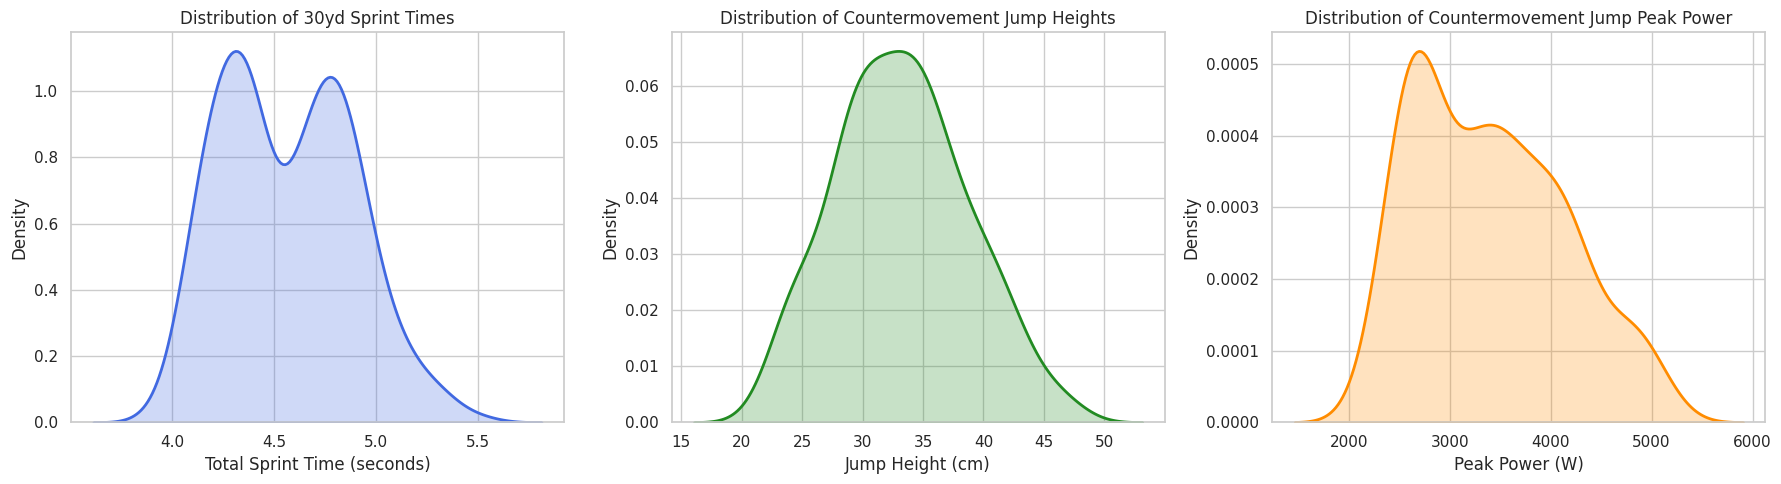

In [ ]:
# =======================================
#  Code generated or assisted by Claude
# =======================================
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Create a figure with 3 subplots side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Density Plot for Sprint Time (Total)
sns.kdeplot(data=speed_df_cleaned, x='Total', fill=True, color='royalblue', ax=axes[0], lw=2)
axes[0].set_title('Distribution of 30yd Sprint Times')
axes[0].set_xlabel('Total Sprint Time (seconds)')
axes[0].set_ylabel('Density')

# 2. Density Plot for Jump Height
sns.kdeplot(data=cmj_df_cleaned, x='Jump Height (Imp-Mom) [cm] ', fill=True, color='forestgreen', ax=axes[1], lw=2)
axes[1].set_title('Distribution of Countermovement Jump Heights')
axes[1].set_xlabel('Jump Height (cm)')
axes[1].set_ylabel('Density')

# 3. Density Plot for Peak Power
sns.kdeplot(data=cmj_df_cleaned, x='Peak Power [W] ', fill=True, color='darkorange', ax=axes[2], lw=2)
axes[2].set_title('Distribution of Countermovement Jump Peak Power')
axes[2].set_xlabel('Peak Power (W)')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()

## 📓Lab Note

Copy the density plots (aka histograms) and paste it onto your lab write-up.

## 📊 Data Visualization: Sprint Time vs. Jump Height

Let's visualize the relationship between 30-yard **sprint time** and **jump height** using a scatter plot. This can help us understand if there's any correlation between these two variables.

###✋ GenAI prompt ###
Generate code that creates a scatter plot of sprint time and jump height on the y and x axes, respectively. Add the coefficient of determination value and the regression line on the plot to indicate the strength of the high performance testing metric in predicting sprint time.

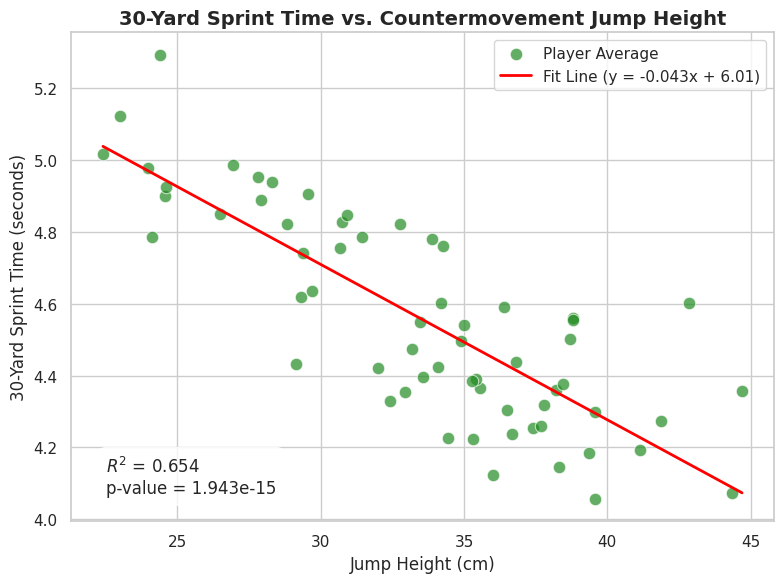

In [ ]:
# =======================================
#  Code generated or assisted by Claude
# =======================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import urllib.request

# Define directories and file paths
data_dir = "kin4042/lab3"
os.makedirs(data_dir, exist_ok=True)

cmj_path = os.path.join(data_dir, "plnu_hp_cmj.csv")
speed_path = os.path.join(data_dir, "plnu_hp_smartspeed_30yd.csv")

# Download files if they do not exist
if not os.path.exists(speed_path) or not os.path.exists(cmj_path):
    cmj_url = "https://raw.githubusercontent.com/plnu-biomechanics/kin4042/refs/heads/main/labs/plnu_hp_cmj.csv"
    speed_url = "https://raw.githubusercontent.com/plnu-biomechanics/kin4042/refs/heads/main/labs/plnu_hp_smartspeed_30yd.csv"
    urllib.request.urlretrieve(cmj_url, cmj_path)
    urllib.request.urlretrieve(speed_url, speed_path)

# Load DataFrames
speed_df = pd.read_csv(speed_path)
cmj_df = pd.read_csv(cmj_path)

# Clean Speed DataFrame using IQR
Q1_speed = speed_df['Total'].quantile(0.25)
Q3_speed = speed_df['Total'].quantile(0.75)
IQR_speed = Q3_speed - Q1_speed
speed_df_cleaned = speed_df[(speed_df['Total'] >= Q1_speed - 1.5 * IQR_speed) & (speed_df['Total'] <= Q3_speed + 1.5 * IQR_speed)]

# Clean CMJ DataFrame using IQR
cmj_df_cleaned = cmj_df.copy()
for col in ['Jump Height (Imp-Mom) [cm] ', 'Peak Power [W] ']:
    Q1_cmj = cmj_df_cleaned[col].quantile(0.25)
    Q3_cmj = cmj_df_cleaned[col].quantile(0.75)
    IQR_cmj = Q3_cmj - Q1_cmj
    cmj_df_cleaned = cmj_df_cleaned[(cmj_df_cleaned[col] >= Q1_cmj - 1.5 * IQR_cmj) & (cmj_df_cleaned[col] <= Q3_cmj + 1.5 * IQR_cmj)]

# 1. Aggregate trials by player (subject_uuid) to get mean sprint time and mean jump height
player_speed = speed_df_cleaned.groupby('subject_uuid')['Total'].mean().reset_index()
player_cmj = cmj_df_cleaned.groupby('subject_uuid')['Jump Height (Imp-Mom) [cm] '].mean().reset_index()

# 2. Merge the datasets on subject_uuid
merged_df = pd.merge(player_speed, player_cmj, on='subject_uuid')

# Extract x and y variables
x = merged_df['Jump Height (Imp-Mom) [cm] ']
y = merged_df['Total']

# 3. Calculate the linear regression parameters
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
r_squared = r_value ** 2

# 4. Create the scatter plot with regression line
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Scatter plot of the data
sns.scatterplot(x=x, y=y, color='forestgreen', alpha=0.7, s=80, label='Player Average')

# Regression line plotting
x_range = np.linspace(x.min(), x.max(), 100)
y_pred = slope * x_range + intercept
plt.plot(x_range, y_pred, color='red', lw=2, label=f'Fit Line (y = {slope:.3f}x + {intercept:.2f})')

# Titles and Labels
plt.title('30-Yard Sprint Time vs. Countermovement Jump Height', fontsize=14, fontweight='bold')
plt.xlabel('Jump Height (cm)', fontsize=12)
plt.ylabel('30-Yard Sprint Time (seconds)', fontsize=12)

# Annotate the R-squared value on the plot
plt.text(
    0.05, 0.05,
    f'$R^2$ = {r_squared:.3f}\np-value = {p_value:.3e}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8)
)

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 📓Lab Note

Copy the scatter plot and paste it onto your lab write-up.

## 📊 Data Visualization: Speed Time vs. Peak Force

Let's visualize the relationship between **speed time** and **peak power** using a scatter plot. This can help us understand if there's any correlation between these two variables.

###✋ GenAI prompt ###
Generate code that creates a scatter plot of speed time and CMJ peak power on the y and x axes, respectively. Add the coefficient of determination value and regression line on the plot to indicate the strength of the high performance testing metric on speed time.

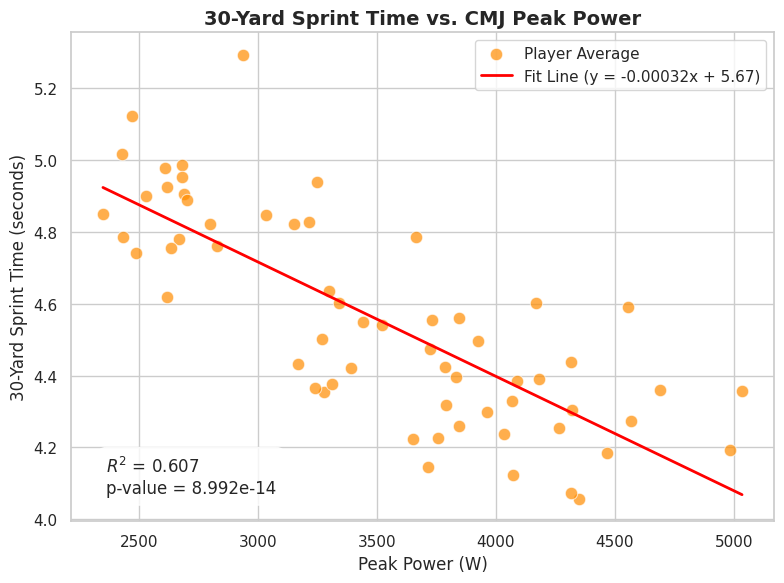

In [ ]:
# **********************************
# ENTER YOUR AI-ASSISTED CODE BELOW
# **********************************



## 📓Lab Note

Copy the scatter plot and paste it onto your lab write-up.

## 📔 Final Notes ##

☝ Notice in these last couple of prompts, the actual names of the sprint time and CMJ metrics were not used. By now, the AI agent knows the exact names of the variables of interest so there's no need to list them exactly in your prompts (but it helps!). Based on the plots and R^2 values, which CMJ metric is more predictive of sprint time?

💡 **What other high performance CMJ testing metrics can predict sprint time?**

Let's put your vibe code skills to the test and complete the lab by selecting two more potential sprint time predictors from `cmj_df` using the same approach we did for jump height and peak power. Use the above prompts and/or code to generate the scatter plots of your selected independent variables.




In [ ]:
# **********************************
# ENTER YOUR AI-ASSISTED CODE BELOW
# **********************************